# SONG incremental behavior and stability

The [paper](https://arxiv.org/abs/1912.04896) emphasizes incremental addition of homogeneous and heterogeneous data while preserving previous visualization structure. This notebook checks the **unmodified** current branch first. With NumPy 2.4.6, the second `fit` raises on `np.int`. It then uses a clearly labeled, process-local alias solely to explore the subsequent behavior; this does **not** change the repository source or count as a passing compatibility result.

Old-point drift is measured after translation/rotation alignment using normalized Procrustes RMS. Lower is more stable. This toy synthetic data is a smoke check; it is not the paper's MNIST experiment. The reported runtime excludes JIT warm-up.

In [1]:
import os, sys, time, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import orthogonal_procrustes
from sklearn.datasets import make_blobs
from sklearn.manifold import trustworthiness
from song.song import SONG
fig_dir = Path('reports/figures')
fig_dir.mkdir(parents=True, exist_ok=True)
print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| threads', os.environ.get('NUMBA_NUM_THREADS', '(default)'))
X, labels = make_blobs(n_samples=360, centers=4, n_features=12, cluster_std=.9, random_state=42)
X = ((X-X.min(0))/(X.max(0)-X.min(0))).astype(np.float32)
old, new = X[labels < 2], X[labels >= 2]
print('Initial', old.shape, '| heterogeneous increment', new.shape)


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.11.15 | NumPy 2.4.6 | threads 2
Initial (180, 12) | heterogeneous increment (180, 12)


In [2]:
# Record the actual current-branch failure before any workaround.
model = SONG(so_steps=10, final_vector_count=40, chunk_size=128, random_seed=42, dispersion_method='none')
t0 = time.perf_counter()
model.fit(old)
initial_fit_s = time.perf_counter()-t0
old_before = model.transform(old).copy()
initial_prototypes = len(model.W)
t0 = time.perf_counter()
try:
    model.fit(new)
    incremental_status = 'unexpected pass'
except Exception as error:
    incremental_status = f'{type(error).__name__}: {error}'.split('\n')[0]
incremental_attempt_s = time.perf_counter()-t0
print('First fit:', round(initial_fit_s,3), 's; second fit:', incremental_status)
assert "AttributeError" in incremental_status and "numpy" in incremental_status and "int" in incremental_status


First fit: 2.505 s; second fit: AttributeError: module 'numpy' has no attribute 'int'.


In [3]:
# Exploratory compatibility shim only. Remove when source code is fixed.
np.int = int
try:
    t0 = time.perf_counter()
    model.fit(new)
    shimmed_fit_s = time.perf_counter()-t0
    old_after = model.transform(old).copy()
    new_after = model.transform(new).copy()
finally:
    del np.int

A = old_before - old_before.mean(0)
B = old_after - old_after.mean(0)
R, _ = orthogonal_procrustes(B, A)
B_aligned = B @ R
scale = np.sqrt(np.mean(np.sum(A*A, axis=1)))
drift = float(np.sqrt(np.mean(np.sum((A-B_aligned)**2, axis=1))) / scale)
summary = pd.DataFrame([{'first_fit_s':initial_fit_s, 'unmodified_second_fit_s':incremental_attempt_s,
                         'unmodified_second_fit':incremental_status, 'shimmed_second_fit_s':shimmed_fit_s,
                         'aligned_old_point_drift':drift, 'initial_prototypes':initial_prototypes,
                         'final_prototypes':len(model.W)}])
display(summary.round(3))
summary.to_csv('reports/incremental_baseline.csv', index=False)


,first_fit_s,unmodified_second_fit_s,unmodified_second_fit,shimmed_second_fit_s,aligned_old_point_drift,initial_prototypes,final_prototypes
0,2.505,0.0,AttributeError: module 'numpy' has no attribut...,0.006,0.937,25,48


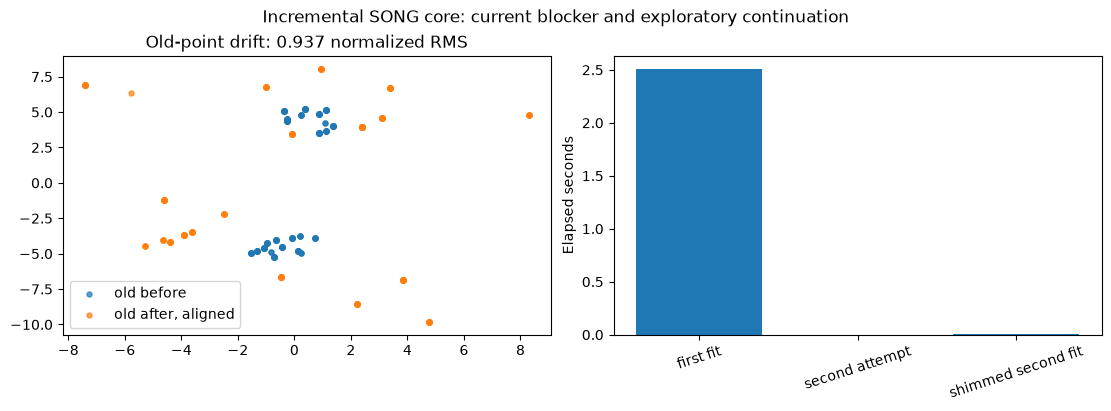

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].scatter(A[:,0], A[:,1], s=13, alpha=.7, label='old before')
axes[0].scatter(B_aligned[:,0], B_aligned[:,1], s=13, alpha=.7, label='old after, aligned')
axes[0].set_title(f'Old-point drift: {drift:.3f} normalized RMS')
axes[0].legend()
axes[1].bar(['first fit', 'second attempt', 'shimmed second fit'],
            [initial_fit_s, incremental_attempt_s, shimmed_fit_s])
axes[1].set_ylabel('Elapsed seconds')
axes[1].tick_params(axis='x', rotation=18)
fig.suptitle('Incremental SONG core: current blocker and exploratory continuation')
fig.savefig(fig_dir / 'incremental_behavior.png', dpi=150)
plt.show()

## Correctness note

The process-local alias gets past the deprecated NumPy name so we can inspect later behavior. It does not validate incremental correctness. `dispersion_method='none'` isolates SONG's map; the default UMAP dispersion separately re-fits an embedding on each `transform`, which needs a stable-reference test before it can be used to evaluate incremental visual consistency. A production regression suite should cover both modes, homogeneous and heterogeneous increments, unchanged old coordinates, deterministic seeds and held-out transforms.